# SMS Spam Classification using SVM
Dataset: https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset?resource=download

In [1]:
# Install (if needed)
!pip -q install wordcloud nltk scikit-learn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from wordcloud import WordCloud
import re, string, nltk
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score,classification_report,
confusion_matrix,ConfusionMatrixDisplay,
precision_score,recall_score,f1_score,roc_curve,auc)

nltk.download('stopwords')
nltk.download('wordnet')
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


## Upload dataset (`spam.csv`) downloaded from Kaggle.

In [3]:
from google.colab import files
uploaded = files.upload()

Saving SMS.csv to SMS (1).csv


In [4]:
df = pd.read_csv("SMS.csv", encoding="latin-1")

df = df[['v1', 'v2']]

df.columns = ['label', 'message']

In [5]:
print(df.shape)
print(df.info())
print(df.isnull().sum())
print("Duplicates:",df.duplicated().sum())
print(df['label'].value_counts())

(5572, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None
label      0
message    0
dtype: int64
Duplicates: 403
label
ham     4825
spam     747
Name: count, dtype: int64


## Exploratory Data Analysis

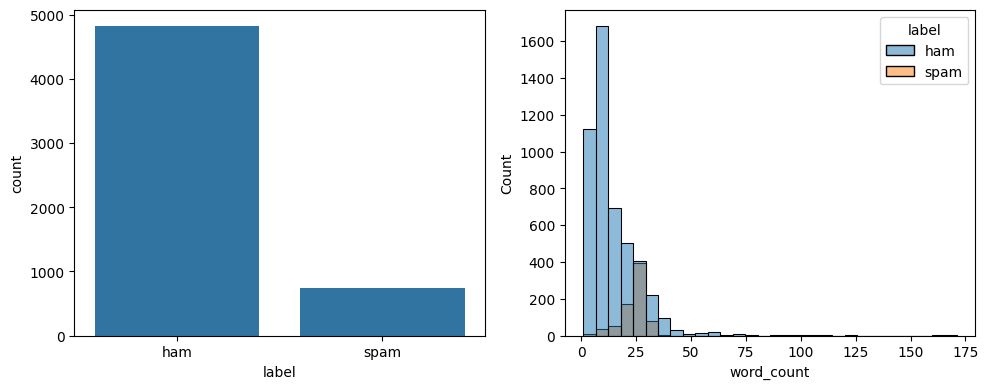

In [6]:
df['char_count']=df['message'].str.len()
df['word_count']=df['message'].str.split().str.len()

fig,ax=plt.subplots(1,2,figsize=(10,4))
sns.countplot(data=df,x='label',ax=ax[0])
sns.histplot(data=df,x='word_count',hue='label',bins=30,ax=ax[1])
plt.tight_layout()
plt.show()

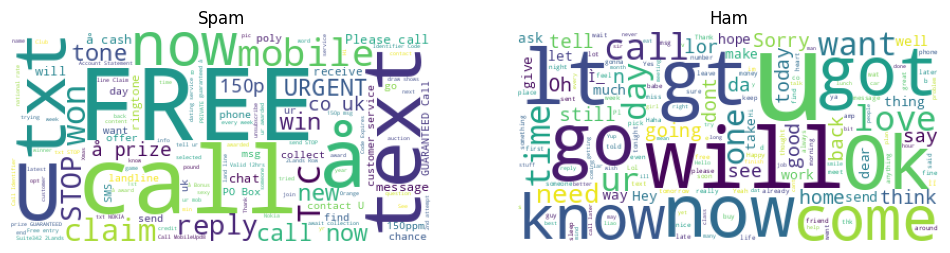

In [7]:
spam=' '.join(df[df.label=='spam'].message)
ham=' '.join(df[df.label=='ham'].message)

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.imshow(WordCloud(background_color='white').generate(spam))
plt.axis('off'); plt.title("Spam")
plt.subplot(1,2,2)
plt.imshow(WordCloud(background_color='white').generate(ham))
plt.axis('off'); plt.title("Ham")
plt.show()

## Preprocessing

In [8]:
# Load the list of English stopwords (e.g., "the", "is", "and")
stop_words = set(stopwords.words('english'))

# Create a WordNet lemmatizer object to convert words to their base form
lemm = WordNetLemmatizer()

# Define a function to clean and preprocess SMS text
def clean_text(text):

    # Convert all characters to lowercase
    text = text.lower()

    # Remove URLs (e.g., http://example.com or www.example.com)
    text = re.sub(r'http\S+|www\S+', ' ', text)

    # Remove email addresses (e.g., abc@gmail.com)
    text = re.sub(r'\S+@\S+', ' ', text)

    # Remove all numeric digits from the text
    text = re.sub(r'\d+', ' ', text)

    # Remove punctuation marks such as !, ?, ., ,, :, etc.
    text = text.translate(str.maketrans('', '', string.punctuation))

    # Split the sentence into words, remove stopwords, lemmatize
    tokens = [
        lemm.lemmatize(word)
        for word in text.split()
        if word not in stop_words
    ]

    # Join the cleaned words back into a single string
    return ' '.join(tokens)

# Remove duplicate SMS messages from the dataset
df = df.drop_duplicates()

# Clean every message
df['clean_message'] = df['message'].apply(clean_text)

# ham -> 0, spam -> 1
df['label'] = df['label'].map({
    'ham': 0,
    'spam': 1
})

df.head()

,label,message,char_count,word_count,clean_message
0,0,"Go until jurong point, crazy.. Available only ...",111,20,go jurong point crazy available bugis n great ...
1,0,Ok lar... Joking wif u oni...,29,6,ok lar joking wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,28,free entry wkly comp win fa cup final tkts st ...
3,0,U dun say so early hor... U c already then say...,49,11,u dun say early hor u c already say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,13,nah dont think go usf life around though


## Train/Test Split

In [9]:
from sklearn.model_selection import train_test_split

X = df['clean_message']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(4135,)
(1034,)


## SVM Model

In [10]:
pipeline=Pipeline([
('tfidf',TfidfVectorizer(max_features=5000,ngram_range=(1,2))),
('svm',LinearSVC())
])

pipeline.fit(X_train,y_train)
pred=pipeline.predict(X_test)

print("Accuracy:",accuracy_score(y_test,pred))
print("Precision:",precision_score(y_test,pred))
print("Recall:",recall_score(y_test,pred))
print("F1:",f1_score(y_test,pred))
print(classification_report(y_test,pred))

Accuracy: 0.9845261121856866
Precision: 0.9831932773109243
Recall: 0.8931297709923665
F1: 0.936
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       903
           1       0.98      0.89      0.94       131

    accuracy                           0.98      1034
   macro avg       0.98      0.95      0.96      1034
weighted avg       0.98      0.98      0.98      1034



## Hyperparameter Tuning

In [11]:
param_grid={
'svm__C':[0.1,1,10]
}
grid=GridSearchCV(pipeline,param_grid,cv=5,n_jobs=-1)
grid.fit(X_train,y_train)

print("Best Parameters:",grid.best_params_)
print("Best CV Score:",grid.best_score_)

Best Parameters: {'svm__C': 1}
Best CV Score: 0.9787182587666263


## Cross Validation

In [12]:
scores=cross_val_score(grid.best_estimator_,df['clean_message'],df['label'],cv=5)
print(scores)
print("Mean Accuracy:",scores.mean())

[0.98162476 0.9787234  0.98065764 0.98162476 0.97483059]
Mean Accuracy: 0.9794922302883003


## Prediction Function

In [13]:
model=grid.best_estimator_

def predict_sms(text):
    pred=model.predict([clean_text(text)])[0]
    return "Spam" if pred==1 else "Ham"

print(predict_sms("Congratulations! You have won a free iPhone. Click here now."))
print(predict_sms("Hi, are we meeting tomorrow at 3 PM?"))

Spam
Ham


# New Features
1. Handcrafted features (URL, currency, digits, caps ratio, spam keywords) combined with TF-IDF
2. Class-imbalance handling (`class_weight='balanced'`)
3. Model comparison (SVM vs Logistic Regression vs Naive Bayes)
4. Calibrated spam probability
5. Threshold tuning to improve recall
6. Confusion matrix, ROC and Precision-Recall curves
7. Error analysis (false positives / false negatives)
8. Top spam / ham words
9. Prediction with confidence + flags, batch prediction to CSV
10. Save / load model

In [14]:
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, MaxAbsScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import precision_recall_curve, average_precision_score
import joblib

## 1. Handcrafted Features

In [15]:
feature_names = ['char_len','word_count','digit_count','upper_ratio','currency_count',
                 'exclaim_count','has_url','has_spam_word','has_long_number']

SPAM_WORDS = r'\b(?:free|win|winner|won|prize|claim|urgent|cash|txt|call now|congratulations|reply|offer|guaranteed)\b'

def extract_features(X):
    msg = X['message'].astype(str)
    return np.column_stack([
        msg.str.len(),
        msg.str.split().str.len(),
        msg.str.count(r'\d'),
        msg.apply(lambda s: sum(c.isupper() for c in s) / max(len(s), 1)),
        msg.str.count(r'[\u00a3$\u20ac]'),
        msg.str.count('!'),
        msg.str.contains(r'http|www', case=False).astype(int),
        msg.str.contains(SPAM_WORDS, case=False).astype(int),
        msg.str.contains(r'\d{5,}').astype(int),
    ])

feat_df = pd.DataFrame(extract_features(df[['message']]), columns=feature_names)
feat_df['label'] = df['label'].values
display(feat_df.groupby('label').mean().T.rename(columns={0:'ham', 1:'spam'}))

label,ham,spam
char_len,70.459256,137.891271
word_count,14.134632,23.681470
digit_count,0.290301,15.447167
upper_ratio,0.058097,0.109991
currency_count,0.005093,0.415008
exclaim_count,0.174712,0.693721
has_url,0.000443,0.139357
has_spam_word,0.032994,0.666156
has_long_number,0.000664,0.765697


In [16]:
def make_preprocessor():
    return ColumnTransformer([
        ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1,2), sublinear_tf=True), 'clean_message'),
        ('num', Pipeline([
            ('feat', FunctionTransformer(extract_features)),
            ('scale', MaxAbsScaler())
        ]), ['message'])
    ])

X_all = df[['message', 'clean_message']]
y_all = df['label']

# same split as before (same random_state + stratify)
X_train_f, X_test_f, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.20, random_state=42, stratify=y_all
)
skf = StratifiedKFold(5, shuffle=True, random_state=42)
print(X_train_f.shape, X_test_f.shape)

(4135, 2) (1034, 2)


## 2. Model Comparison (5-fold CV on training data)

In [17]:
models = {
    'LinearSVC (balanced)': LinearSVC(class_weight='balanced'),
    'LogisticRegression (balanced)': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'MultinomialNB': MultinomialNB(),
}

rows = []
for name, clf in models.items():
    p = Pipeline([('pre', make_preprocessor()), ('clf', clf)])
    cv = cross_validate(p, X_train_f, y_train, cv=skf,
                        scoring=['accuracy','precision','recall','f1'], n_jobs=-1)
    rows.append({
        'model': name,
        'accuracy':  cv['test_accuracy'].mean(),
        'precision': cv['test_precision'].mean(),
        'recall':    cv['test_recall'].mean(),
        'f1':        cv['test_f1'].mean(),
    })

comparison = pd.DataFrame(rows).set_index('model').round(4)
display(comparison)

,accuracy,precision,recall,f1
model,,,,
LinearSVC (balanced),0.9860,0.9642,0.9233,0.9431
LogisticRegression (balanced),0.9807,0.9258,0.9214,0.9233
MultinomialNB,0.9855,0.9773,0.9061,0.9403


## 3. Tuned + Calibrated Model (gives spam probability)

In [18]:
base = Pipeline([('pre', make_preprocessor()), ('svm', LinearSVC(class_weight='balanced'))])
grid2 = GridSearchCV(base, {'svm__C': [0.1, 0.5, 1, 2, 5, 10]},
                     cv=skf, scoring='f1', n_jobs=-1)
grid2.fit(X_train_f, y_train)
best_C = grid2.best_params_['svm__C']
print("Best C:", best_C, "| Best CV F1:", round(grid2.best_score_, 4))

final_model = Pipeline([
    ('pre', make_preprocessor()),
    ('clf', CalibratedClassifierCV(LinearSVC(C=best_C, class_weight='balanced'), cv=5))
])
final_model.fit(X_train_f, y_train)

Best C: 0.5 | Best CV F1: 0.9472


Pipeline(steps=[('pre',
                 ColumnTransformer(transformers=[('tfidf',
                                                  TfidfVectorizer(max_features=5000,
                                                                  ngram_range=(1,
                                                                               2),
                                                                  sublinear_tf=True),
                                                  'clean_message'),
                                                 ('num',
                                                  Pipeline(steps=[('feat',
                                                                   FunctionTransformer(func=<function extract_features at 0x79e41cce0fe0>)),
                                                                  ('scale',
                                                                   MaxAbsScaler())]),
                                                  ['message'])])),
                ('clf',
                 CalibratedClassifierCV(cv=5,
                                        estimator=LinearSVC(C=0.5,
                                                            class_weight='balanced')))])

## 4. Threshold Tuning (maximise F1 using cross-validated probabilities)

Best threshold: 0.327 | CV F1: 0.9483


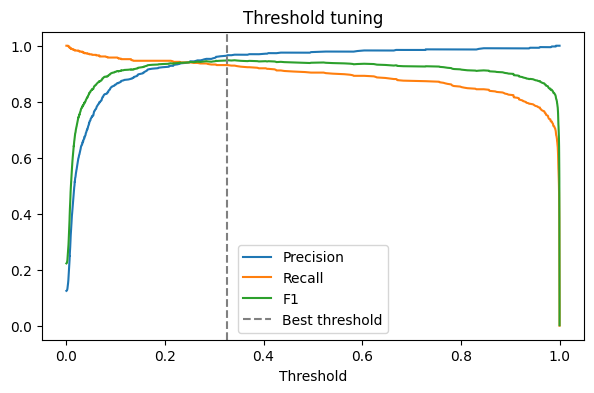

In [19]:
oof = cross_val_predict(final_model, X_train_f, y_train, cv=skf,
                        method='predict_proba', n_jobs=-1)[:, 1]

prec, rec, thr = precision_recall_curve(y_train, oof)
f1s = 2 * prec * rec / (prec + rec + 1e-9)
best_idx = np.argmax(f1s[:-1])
best_thr = float(thr[best_idx])
print("Best threshold:", round(best_thr, 3), "| CV F1:", round(f1s[best_idx], 4))

plt.figure(figsize=(7,4))
plt.plot(thr, prec[:-1], label='Precision')
plt.plot(thr, rec[:-1], label='Recall')
plt.plot(thr, f1s[:-1], label='F1')
plt.axvline(best_thr, color='gray', linestyle='--', label='Best threshold')
plt.xlabel('Threshold'); plt.legend(); plt.title('Threshold tuning')
plt.show()

## 5. Evaluation on Test Set

=== Default threshold (0.5) ===
              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       903
        spam       0.99      0.92      0.95       131

    accuracy                           0.99      1034
   macro avg       0.99      0.96      0.97      1034
weighted avg       0.99      0.99      0.99      1034

=== Tuned threshold (0.327) ===
              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       903
        spam       0.97      0.93      0.95       131

    accuracy                           0.99      1034
   macro avg       0.98      0.96      0.97      1034
weighted avg       0.99      0.99      0.99      1034



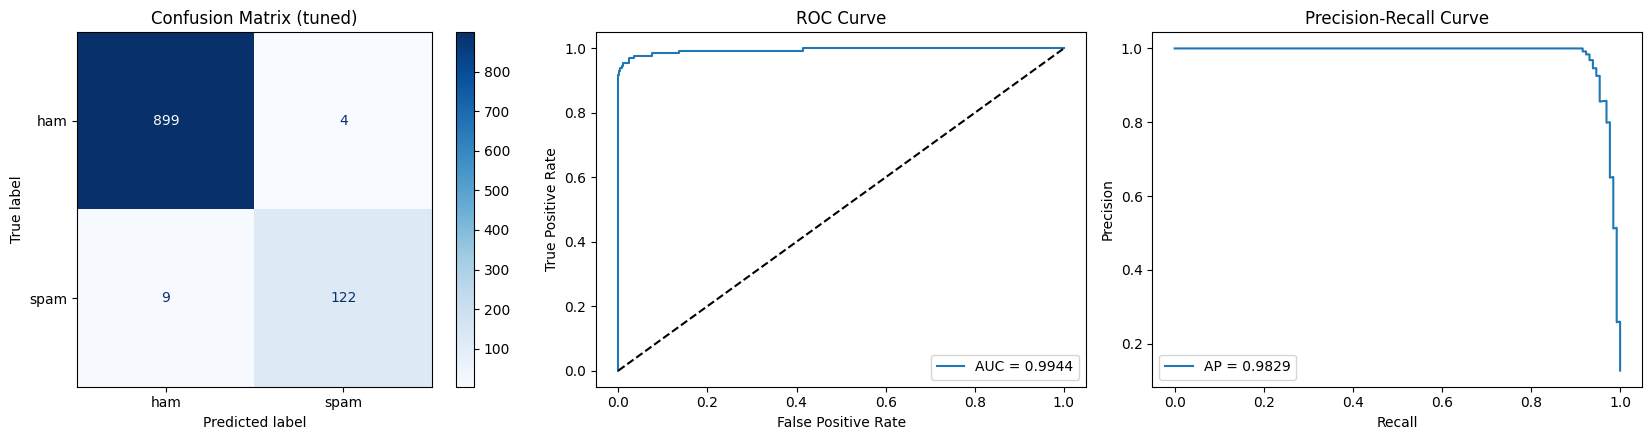

In [20]:
proba = final_model.predict_proba(X_test_f)[:, 1]
pred_default = (proba >= 0.5).astype(int)
pred_tuned = (proba >= best_thr).astype(int)

print("=== Default threshold (0.5) ===")
print(classification_report(y_test, pred_default, target_names=['ham','spam']))
print("=== Tuned threshold (%.3f) ===" % best_thr)
print(classification_report(y_test, pred_tuned, target_names=['ham','spam']))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

ConfusionMatrixDisplay.from_predictions(y_test, pred_tuned, display_labels=['ham','spam'],
                                        cmap='Blues', ax=ax[0])
ax[0].set_title('Confusion Matrix (tuned)')

fpr, tpr, _ = roc_curve(y_test, proba)
ax[1].plot(fpr, tpr, label='AUC = %.4f' % auc(fpr, tpr))
ax[1].plot([0,1], [0,1], 'k--')
ax[1].set_xlabel('False Positive Rate'); ax[1].set_ylabel('True Positive Rate')
ax[1].set_title('ROC Curve'); ax[1].legend()

p_, r_, _ = precision_recall_curve(y_test, proba)
ax[2].plot(r_, p_, label='AP = %.4f' % average_precision_score(y_test, proba))
ax[2].set_xlabel('Recall'); ax[2].set_ylabel('Precision')
ax[2].set_title('Precision-Recall Curve'); ax[2].legend()

plt.tight_layout()
plt.show()

## 6. Error Analysis

In [21]:
errors = X_test_f.assign(true=y_test.values, spam_prob=proba.round(3), pred=pred_tuned)
pd.set_option('display.max_colwidth', 140)

print("False negatives (spam predicted as ham):")
display(errors[(errors.true == 1) & (errors.pred == 0)][['message','spam_prob']])

print("False positives (ham predicted as spam):")
display(errors[(errors.true == 0) & (errors.pred == 1)][['message','spam_prob']])

False negatives (spam predicted as ham):


,message,spam_prob
671,SMS. ac sun0819 posts HELLO:\You seem cool,0.071
2401,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about we go slo n hard! Tx...,0.205
4819,Check Out Choose Your Babe Videos @ sms.shsex.netUN fgkslpoPW fgkslpo,0.107
4142,"In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Day, C-Red Day. (Send ...",0.034
4392,RECPT 1/3. You have ordered a Ringtone. Your order is being processed...,0.247
3528,"Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am till 8pm, and on Thurs, Fri & Sat night this week. ...",0.116
5449,"Latest News! Police station toilet stolen, cops have nothing to go on!",0.007
1874,Would you like to see my XXX pics they are so hot they were nearly banned in the uk!,0.019
2769,Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and go Large or Super with Coca-Cola and walk out a w...,0.307


False positives (ham predicted as spam):


,message,spam_prob
1855,K.:)you are the only girl waiting in reception ah?,0.428
759,"Call me when you/carlos is/are here, my phone's vibrate is acting up and I might not hear texts",0.351
1289,"Hey...Great deal...Farm tour 9am to 5pm $95/pax, $50 deposit by 16 May",0.507
3873,No. Did you multimedia message them or e-mail?,0.387


## 7. Top Spam / Ham Words

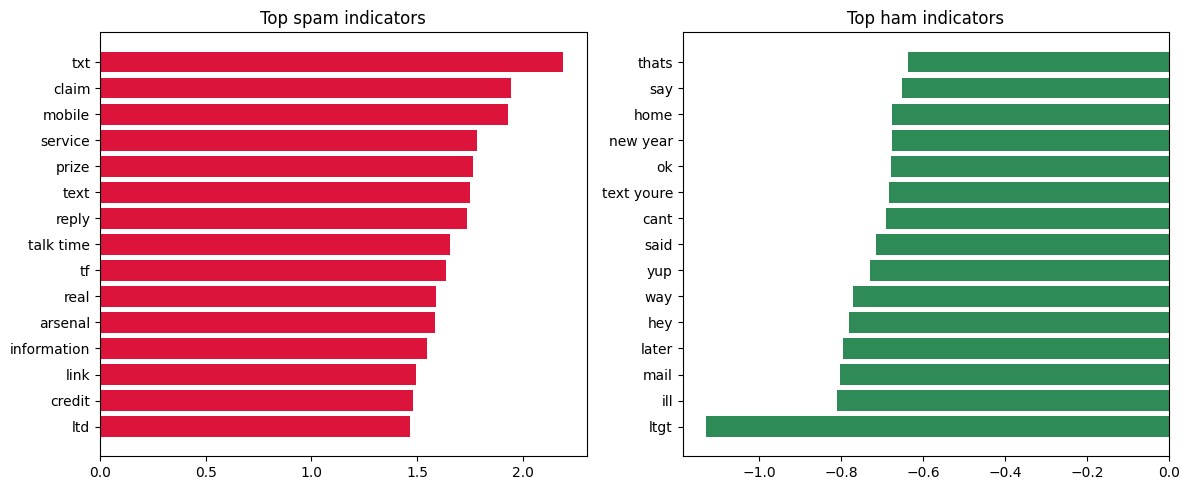

In [22]:
vec = TfidfVectorizer(max_features=5000, ngram_range=(1,2), sublinear_tf=True)
Xv = vec.fit_transform(X_train_f['clean_message'])
lin = LinearSVC(class_weight='balanced').fit(Xv, y_train)

coefs = lin.coef_[0]
names = np.array(vec.get_feature_names_out())
top_spam = np.argsort(coefs)[-15:]
top_ham = np.argsort(coefs)[:15]

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].barh(names[top_spam], coefs[top_spam], color='crimson')
ax[0].set_title('Top spam indicators')
ax[1].barh(names[top_ham], coefs[top_ham], color='seagreen')
ax[1].set_title('Top ham indicators')
plt.tight_layout()
plt.show()

## 8. Prediction with Confidence, Flags and Batch Mode

In [23]:
def get_flags(text):
    f = extract_features(pd.DataFrame({'message': [text]}))[0]
    flags = []
    if f[6]: flags.append('contains link')
    if f[7]: flags.append('spam keyword')
    if f[4]: flags.append('currency symbol')
    if f[8]: flags.append('long number/phone')
    if f[3] > 0.3: flags.append('too many capitals')
    if f[5] >= 2: flags.append('multiple !')
    return flags

def predict_sms(text, threshold=best_thr):
    row = pd.DataFrame({'message': [text], 'clean_message': [clean_text(text)]})
    p = float(final_model.predict_proba(row)[0, 1])
    return {
        'label': 'Spam' if p >= threshold else 'Ham',
        'spam_probability': round(p, 4),
        'flags': get_flags(text),
    }

def predict_batch(messages, threshold=best_thr):
    data = pd.DataFrame({'message': list(messages)})
    data['clean_message'] = data['message'].apply(clean_text)
    data['spam_probability'] = final_model.predict_proba(data[['message','clean_message']])[:, 1].round(4)
    data['label'] = np.where(data['spam_probability'] >= threshold, 'Spam', 'Ham')
    return data[['message', 'label', 'spam_probability']]

print(predict_sms("Congratulations! You have won a free iPhone. Click here now."))
print(predict_sms("Hi, are we meeting tomorrow at 3 PM?"))
print(predict_sms("URGENT! Call 09061701461 now to claim your \u00a31000 cash prize!!"))

batch = predict_batch([
    "Free entry in 2 a wkly comp to win FA Cup final tkts",
    "Ok lar... Joking wif u oni...",
    "Your account is suspended. Verify at www.secure-bank.com",
    "Can you send me the notes from today's class?",
])
display(batch)
batch.to_csv('sms_predictions.csv', index=False)

{'label': 'Ham', 'spam_probability': 0.2426, 'flags': ['spam keyword']}
{'label': 'Ham', 'spam_probability': 0.0042, 'flags': []}
{'label': 'Spam', 'spam_probability': 0.9991, 'flags': ['spam keyword', 'currency symbol', 'long number/phone', 'multiple !']}


,message,label,spam_probability
0,Free entry in 2 a wkly comp to win FA Cup final tkts,Ham,0.1198
1,Ok lar... Joking wif u oni...,Ham,0.0032
2,Your account is suspended. Verify at www.secure-bank.com,Spam,0.6631
3,Can you send me the notes from today's class?,Ham,0.0088


## 9. Save / Load Model

In [24]:
joblib.dump({'model': final_model, 'threshold': best_thr}, 'sms_spam_model.joblib')
print("Saved: sms_spam_model.joblib")

# To reuse later (define clean_text and extract_features first, then):
# saved = joblib.load('sms_spam_model.joblib')
# final_model, best_thr = saved['model'], saved['threshold']

try:
    files.download('sms_spam_model.joblib')
except Exception as e:
    print("Download skipped:", e)

Saved: sms_spam_model.joblib


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Interactive Checker (type `quit` to stop)

In [25]:
while True:
    text = input("Enter SMS: ")
    if text.strip().lower() == 'quit':
        break
    print(predict_sms(text))

Enter SMS: quit
